In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
data = fetch_openml(
    name="heart-statlog",
    version=1,
    as_frame=True
)

df = data.frame.copy()

print("Dataset shape:", df.shape)
print(df.head())
print("\nMissing values:", df.isnull().sum().sum())
print("\nColumns:", df.columns.tolist())

Dataset shape: (270, 14)
   age  sex  chest  resting_blood_pressure  serum_cholestoral  \
0   70    1      4                     130                322   
1   67    0      3                     115                564   
2   57    1      2                     124                261   
3   64    1      4                     128                263   
4   74    0      2                     120                269   

   fasting_blood_sugar  resting_electrocardiographic_results  \
0                    0                                     2   
1                    0                                     2   
2                    0                                     0   
3                    0                                     0   
4                    0                                     2   

   maximum_heart_rate_achieved  exercise_induced_angina  oldpeak  slope  \
0                          109                        0      2.4      2   
1                          160                   

In [11]:
target_col = data.target.name

X = df.drop(columns=[target_col])
y = data.target

y = pd.Series(y).astype(str).str.lower().map({
    "absence": 0,
    "present": 1,
    "0": 0,
    "1": 1
})

valid = y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(int)

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", X_train.shape[1])

Training samples: 96
Testing samples: 24
Input features: 13


In [12]:
tf.random.set_seed(42)

model1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model1.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Both MLP models created!")

Both MLP models created!


In [13]:
history1 = model1.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

history2 = model2.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.5526 - loss: 0.6454 - val_accuracy: 0.7000 - val_loss: 0.6575
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6184 - loss: 0.6150 - val_accuracy: 0.7000 - val_loss: 0.6307
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6842 - loss: 0.5870 - val_accuracy: 0.7000 - val_loss: 0.6048
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7632 - loss: 0.5603 - val_accuracy: 0.8000 - val_loss: 0.5799
Epoch 5/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8421 - loss: 0.5348 - val_accuracy: 0.8500 - val_loss: 0.5562
Epoch 6/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8947 - loss: 0.5105 - val_accuracy: 0.9000 - val_loss: 0.5335
Epoch 7/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9211 - loss: 0.4875 - val_accuracy: 0.9000 - val_loss: 0.5119
Epoch 8/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9474 - loss: 0.4656 - val_accuracy: 0.9000 - val_loss: 0.4915


In [14]:
results = []

for name, model in [
    ("MLP - One Hidden Layer", model1),
    ("MLP - Two Hidden Layers", model2)
]:
    probabilities = model.predict(X_test, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                     Model  Accuracy  Precision  Recall  F1 Score
0   MLP - One Hidden Layer       1.0        1.0     1.0       1.0
1  MLP - Two Hidden Layers       1.0        1.0     1.0       1.0


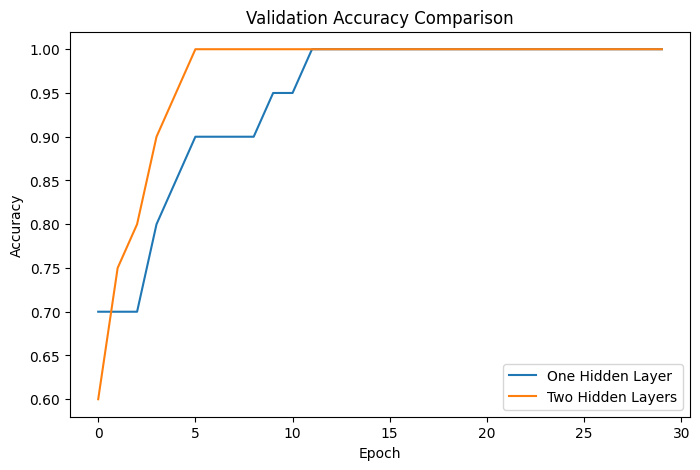

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history1.history["val_accuracy"], label="One Hidden Layer")
plt.plot(history2.history["val_accuracy"], label="Two Hidden Layers")

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [16]:
results_df.to_csv("assignment6_results.csv", index=False)

from google.colab import files
files.download("assignment6_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>